# Retail Sales Prediction ML Project

**📝 Problem Statement**

* The objective of this project is to build an end-to-end predictive machine learning model to estimate product revenue potentials or optimize inventory logistics by forecasting a target market variable—such as optimal pricing, stock thresholds, or distribution logistics—using the product profiles found in the shipping_data_with_outliers.csv dataset. 
* By analyzing structural attributes including product type (Category), operational indicators (Price, Rating, Stock, Discount), and weight profiles (Shipping_weight), the system aims to uncover core drivers of supply chain efficiency. 
* This predictive pipeline handles structural outliers seamlessly, allowing retail operators to optimize stocking levels, protect profit margins from over-discounting, and forecast shipment demands accurately.

**Step 1: Import Libraries**

In [2]:
# System and Data manipulation
import joblib

# Visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

# feature selection
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer

# Regression Models
from sklearn.linear_model import LinearRegression

# Regression Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preprocessing & Selection
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor


**Step 2: Load Dataset**

In [4]:
df = pd.read_csv("shipping_data_with_outliers.csv")

**Step 3: Understand Your Data (EDA)**

In [5]:
print("\n[First 5 Rows Preview]:\n", df.head())


[First 5 Rows Preview]:
   Category   Price    Rating         Stock  Discount  Shipping_weight
0      NaN  5548.0  1.870322           NaN       0.0         4500.000
1      NaN  3045.0  4.757798           NaN      38.0           12.000
2      NaN  4004.0       NaN      In Stock       0.0         5200.000
3      NaN  4808.0  1.492085           NaN      33.0          657.514
4      NaN  1817.0       NaN  Out of Stock      23.0          355.031


In [6]:
print(f"\n[Dataset Dimensions (Rows, Columns)]: {df.shape}")


[Dataset Dimensions (Rows, Columns)]: (4362, 6)


In [12]:
df.dtypes

Category               str
Price              float64
Rating             float64
Stock                  str
Discount           float64
Shipping_weight    float64
dtype: object

In [13]:
df.nunique()

Category              4
Price              3422
Rating             2312
Stock                 2
Discount             50
Shipping_weight    4350
dtype: int64

In [14]:
print(f"Columns: \n{df.columns}")

Columns: 
Index(['Category', 'Price', 'Rating', 'Stock', 'Discount', 'Shipping_weight'], dtype='str')


In [8]:
print("\n[Data Types and Structural Check]:\n")
df.info()


[Data Types and Structural Check]:

<class 'pandas.DataFrame'>
RangeIndex: 4362 entries, 0 to 4361
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Category         1614 non-null   str    
 1   Price            4188 non-null   float64
 2   Rating           2312 non-null   float64
 3   Stock            3010 non-null   str    
 4   Discount         3970 non-null   float64
 5   Shipping_weight  4362 non-null   float64
dtypes: float64(4), str(2)
memory usage: 236.6 KB


In [10]:
print("\n[Descriptive Statistical Summary]:\n")
df.describe().T


[Descriptive Statistical Summary]:



,count,mean,std,min,25%,50%,75%,max
Price,4188.0,5016.970630,2839.984813,102.000000,2628.25000,4996.50000,7418.00000,9999.000000
Rating,2312.0,3.038293,1.143074,1.000366,2.06949,3.08206,4.00862,4.997818
Discount,3970.0,24.516625,14.347164,0.000000,12.00000,25.00000,37.00000,49.000000
Shipping_weight,4362.0,550.511660,276.821159,12.000000,323.87275,550.73600,772.89575,5200.000000


In [11]:
# Target Variable Analysis (Assuming 'Price' is our target for optimization / valuation)
print(f"\n[Target Skewness Profile]: {df['Price'].skew():.2f}")


[Target Skewness Profile]: 0.01


**Step 4: Data Cleaning**

In [17]:
# 1. Remove Duplicates
print(f"Duplicate rows identified: {df.duplicated().sum()}")
df = df.drop_duplicates()

Duplicate rows identified: 0


In [ ]:
# 2. Remove Unwanted Columns
# there no unwanted col

In [18]:
# 3. Check for Missing Values 
print("Missing values per parameter:\n",df.isnull().sum())

Missing values per parameter:
 Category           2748
Price               174
Rating             2050
Stock              1352
Discount            392
Shipping_weight       0
dtype: int64


In [ ]:
# 4. Fix Data Types
# No need

In [ ]:
# 5. Fix proper col names
#df = df.rename(columns={'old':'new'})

<Axes: >

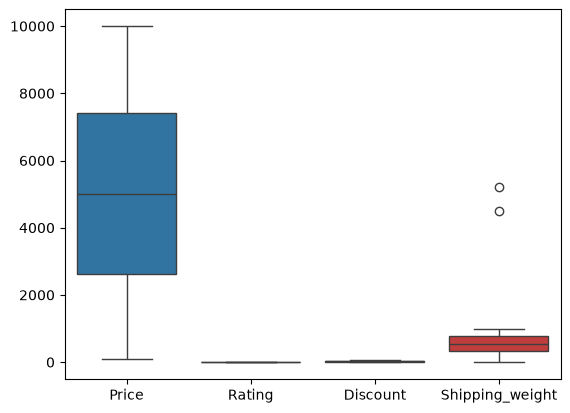

In [ ]:
# 6. Remove outliers

sns.boxplot(df[['Price', 'Rating','Discount','Shipping_weight']])

In [21]:
q1 = df['Shipping_weight'].quantile(0.25)
q3 = df['Shipping_weight'].quantile(0.75)
iqr = q3 - q1

lower = q1 - (1.5 * iqr)
upper = q3 + (1.5 * iqr)

before_outliers = df[(df['Shipping_weight'] < lower) | (df['Shipping_weight'] > upper)]
print("before outliers: ",len(before_outliers))
df['Shipping_weight'] = df['Shipping_weight'].clip(lower,upper)
after_outliers = df[(df['Shipping_weight'] < lower) | (df['Shipping_weight'] > upper)]
print("after outliers: ",len(after_outliers))

before outliers:  2
after outliers:  0


**verify:**

<Axes: >

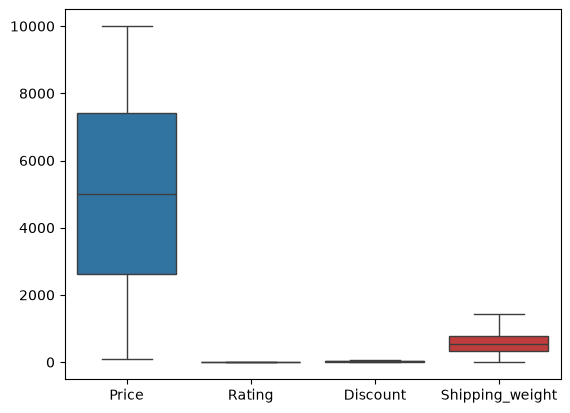

In [22]:
sns.boxplot(df[['Price', 'Rating','Discount','Shipping_weight']])

**Step 5: Feature Engineering**

In [25]:
# Price per unit of shipping weight
df['Value_Weight_Density'] = df['Price'] / (df['Shipping_weight'] + 0.1) # Add small constant to prevent zero division

df['Bargain_Attraction_Index'] = df['Rating'] * df['Discount']

df['Effective_Price'] = df['Price'] * (1 - (df['Discount'] / 100))

**Step 6: Data Visualization**

Univariate:

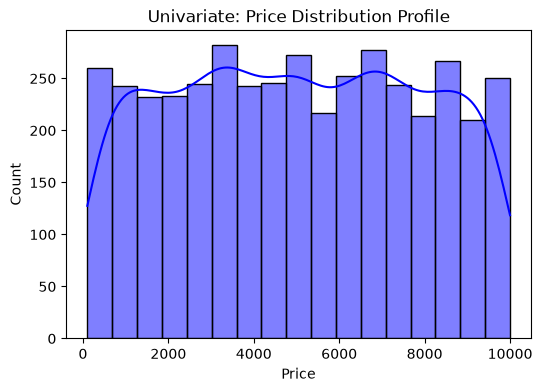

In [26]:
# 1. Univariate: Histogram (Price Distribution Profile)
plt.figure(figsize=(6, 4))
sns.histplot(df['Price'], kde=True, color='blue')
plt.title('Univariate: Price Distribution Profile')
plt.show()

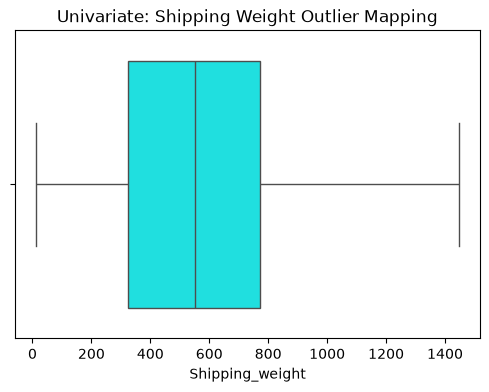

In [27]:
# 2. Univariate: Boxplot (Visualising structural outliers in weights)
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Shipping_weight'], color='cyan')
plt.title('Univariate: Shipping Weight Outlier Mapping')
plt.show()

In [31]:
df.columns

Index(['Category', 'Price', 'Rating', 'Stock', 'Discount', 'Shipping_weight',
       'Value_Weight_Density', 'Bargain_Attraction_Index', 'Effective_Price'],
      dtype='str')

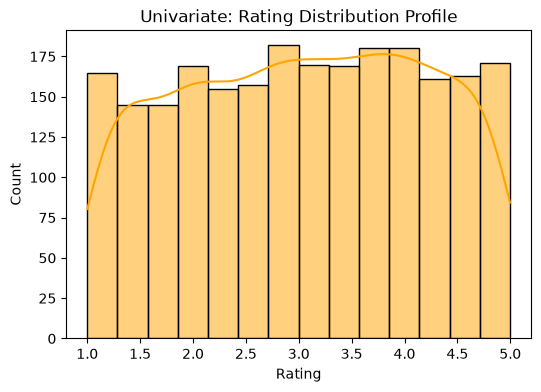

In [ ]:
# 3. Univariate: Histogram (Rating Distribution Profile)
plt.figure(figsize=(6, 4))
sns.histplot(df['Rating'], kde=True, color='orange')
plt.title('Univariate: Rating Distribution Profile')
plt.show()

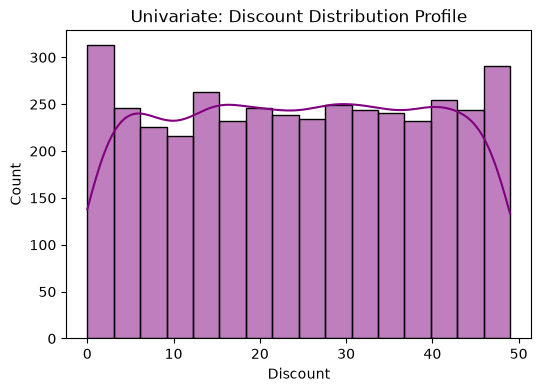

In [33]:
# 3. Univariate: Histogram (Discount Distribution Profile)
plt.figure(figsize=(6, 4))
sns.histplot(df['Discount'], kde=True, color='purple')
plt.title('Univariate: Discount Distribution Profile')
plt.show()

Bivariate & Multivariate:

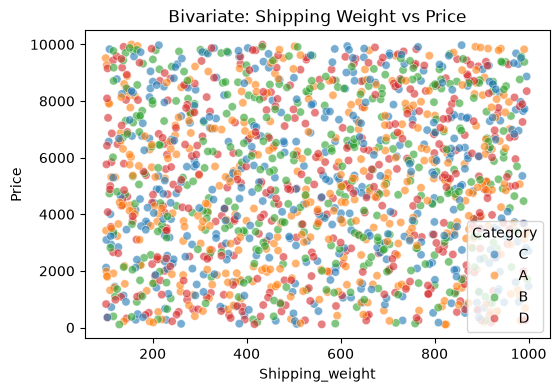

In [29]:
# 3. Bivariate: Scatterplot (Shipping Weight vs Price split by Category)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='Shipping_weight', y='Price', hue='Category', alpha=0.6)
plt.title('Bivariate: Shipping Weight vs Price')
plt.show()

Correlation analysis:

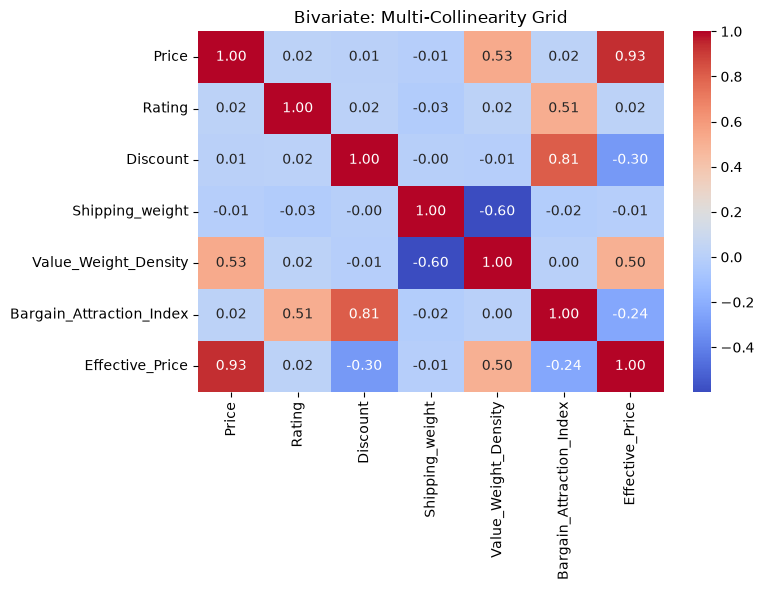

In [30]:
# 4. Bivariate: Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Bivariate: Multi-Collinearity Grid')
plt.tight_layout()
plt.show()

**Imputing for Target col:**

In [41]:
target_imputer = SimpleImputer(strategy='median')

# SimpleImputer expects a 2D array, so we reshape it using .values.reshape(-1, 1)
df['Price'] = target_imputer.fit_transform(df[['Price']])

print(f"Missing values in Price after imputation: {df['Price'].isnull().sum()}")

Missing values in Price after imputation: 0


**Step 7: Define Features (X) and Target (y)**

In [43]:
X = df.drop(columns=['Price'])
y = df['Price']   #Keep the target completely raw since skewness is already perfect (0.01)

numeric_cols = X.select_dtypes(include=[float]).columns.tolist()
categorical_cols = X.select_dtypes(include=[str]).columns.tolist()

**Step 8: Train-Test Split**

In [44]:
# Partition data into 80% Training and 20% Testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

X_train Shape: (3489, 8) | X_test Shape: (873, 8)


**Step 9: Preprocessing Pipeline**

In [45]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

**Step 10: Feature Selection**

In [46]:
# Initialize VarianceThreshold
selector = VarianceThreshold(threshold=0.01)

# Fit and transform the data
X_train_sele = selector.fit_transform(X_train_processed)
X_test_sele = selector.fit_transform(X_test_processed)

print("Original X Train shape:", X_train_processed.shape)
print("Reduced X Train shape:", X_train_sele.shape)
print("Reduced X Test shape:", X_test_sele.shape)

Original X Train shape: (3489, 12)
Reduced X Train shape: (3489, 12)
Reduced X Test shape: (873, 12)


**Step 11 & 12: Train Models & Regression Metrics**

In [47]:
regression_suite = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
}

for name, model in regression_suite.items():
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_test_processed)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    print(f"[{name}] -> R2 Score: {r2*100:.2f}% | MAE: ${mae:.2f} | RMSE: ${rmse:.2f}")


[Linear Regression] -> R2 Score: 89.02% | MAE: $551.39 | RMSE: $931.71
[Decision Tree] -> R2 Score: 99.23% | MAE: $135.56 | RMSE: $247.31
[Random Forest] -> R2 Score: 99.30% | MAE: $104.32 | RMSE: $235.87
[XGBoost Regressor] -> R2 Score: 99.13% | MAE: $140.37 | RMSE: $262.45


**Step 13: Cross Validation**

In [49]:
rf_validator = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
cv_scores = cross_val_score(rf_validator, X_train_processed, y_train, cv=3, scoring='r2')

print(f"3-Fold Cross Validation Individual R2 Matrix: {cv_scores}")
print(f"Mean Generalization R2 Accuracy: {cv_scores.mean()*100:.2f}%")


3-Fold Cross Validation Individual R2 Matrix: [0.99084957 0.99168301 0.98511162]
Mean Generalization R2 Accuracy: 98.92%


**Step 14: Hyperparameter Tuning**

In [51]:
param_distributions = {
    'n_estimators': [100, 130, 150],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [5, 7, 4],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_validator,
    param_distributions=param_distributions,
    n_iter=5, 
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_processed, y_train)
best_tuned_rf = random_search.best_estimator_

print("Optimal Hyperparameter Configurations Found:", random_search.best_params_)


Optimal Hyperparameter Configurations Found: {'n_estimators': 150, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_depth': 20}


In [ ]:
predictions = best_tuned_rf.predict(X_test_processed)
acc = r2_score(y_test, predictions)

print(f"[Tuned Random Forest] -> r2 score: {acc*100:.2f}%")

**Step 15: Feature Importance**

In [52]:
features = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in features], 
    'Importance': best_tuned_rf.feature_importances_                
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.to_string(index=False))



--- TOP FEATURE IMPORTANCE SCORES ---
                 Feature  Importance
         Effective_Price    0.828322
    Value_Weight_Density    0.075077
                Discount    0.069873
         Shipping_weight    0.025277
                  Rating    0.000719
Bargain_Attraction_Index    0.000205
              Category_C    0.000112
          Stock_In Stock    0.000098
              Category_D    0.000093
              Category_A    0.000090
      Stock_Out of Stock    0.000086
              Category_B    0.000049


**Step 16: Final Pipeline Production**

In [53]:
print("Unified Production Pipeline constructed successfully!")
production_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_tuned_rf)
])

production_pipeline.fit(X_train, y_train)

Unified Production Pipeline constructed successfully!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Category','Rating','Stock',...,'Value_Weight_Density', 'Bargain_Attraction_Index','Effective_Price']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passe

**Step 17: Save Model & Load Model**

In [54]:
model_artifact = {
    "model_pipeline": production_pipeline,
    "feature_names": X.columns.tolist()
}

joblib.dump(model_artifact, "retail_rf_production.pkl")
print("Production artifact saved successfully as 'retail_rf_production.pkl'")

Production artifact saved successfully as 'retail_rf_production.pkl'


In [55]:
# --- Quick load verification test pass ---
loaded_bundle = joblib.load("retail_rf_production.pkl")
production_ready_rf_pipeline = loaded_bundle["model_pipeline"]
print("Model validation verified successfully! Ready for server deployment.")

Model validation verified successfully! Ready for server deployment.
